# Introduction to Beautiful Soup

**Seong Cho** · ACME Data Science Essentials, Lab 5

**Lab objective:** extract information from HTML, the first step in web scraping, using BeautifulSoup to navigate and search the HTML tree.

<sub>Lab specification from the *Data Science Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from my lab template; the notes are condensed from the spec. Solutions are my own.</sub>

In [1]:
# """Volume 3: Introduction to BeautifulSoup.
# <Name>
# <Class>
# <Date>
# """
import re
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import requests

> **Note.** My course template had seven problems: `prob1()` (download `example.html` with `requests`) comes first, and `prob2()`–`prob7()` are Problems 1–6 of the August 2018 manual, which is why the template's `# Problem N` comments in the code run one behind the headings here. The headings follow the function names and the grader.

## HTML

**HTML** (Hyper Text Markup Language) is the standard markup language for web pages. Content sits between an opening tag `<tag-name>` and its closing tag `</tag-name>`; tags can carry **attributes** such as `id` or `href` (hypertext reference, a link). Whitespace and indentation don't matter to HTML. Special tags with no content are self-closing, like `<hr/>` and `<img/>`. A list of tags is at http://htmldog.com/reference/htmltags.

```html
<html><body><p>Click <a id='info' href='http://www.example.com/info'>here</a>
for more information.</p></body></html>
```

The `requests` library fetches a page's source: `requests.get(url).text`.

## Problem 1: Download example.html

> **Problem 1.** Use the requests library to get the HTML source for the website http://www.example.com. Save the source as a file called `example.html`. If the file already exists, make sure not to scrape the website, or overwrite the file.

In [2]:
def prob1():
    """
    Use the requests library to get the HTML source for the website http://www.example.com.
    Save the source as a file called 'example.html'. If the file already exists, make
    sure not to scrape the website, or overwrite the file.
    """
    import os.path
    # Check if file exists
    if not os.path.isfile("example.html"):
        # Write example.html
        response = requests.get("http://www.example.com")
        with open("example.html", 'w') as outfile:
            outfile.write(response.text)
            print("File written")
    else:
        raise FileExistsError("example.html already exists")    # Changed: raising a str is a TypeError in Python 3

`example.html` is already saved in this folder, so the function refuses to scrape the site again:

In [3]:
try:
    prob1()
except FileExistsError as e:
    print("FileExistsError:", e)

FileExistsError: example.html already exists


## Problem 2: Tags in example.com

> **Problem 2.** Examine the source code of http://www.example.com. Determine the names of the tags in the code and the value of the 'type' attribute associated with the 'style' tag.

(The spec's hint: there are ten unique tag names.)

In [4]:
# Problem 1
def prob2():
    """Examine the source code of http://www.example.com. Determine the names
    of the tags in the code and the value of the 'type' attribute associated
    with the 'style' tag.

    Returns:
        (set): A set of strings, each of which is the name of a tag.
        (str): The value of the 'type' attribute in the 'style' tag.
    """
    tags = set()
    style_type = None
    # Open example.html, then read each line
    with open("example.html", 'r') as infile:
        for line in infile.readlines():
            # Search for tags
            if re.search(r'</?(\w+) ?.*>', line):
                tags = tags.union(set(re.findall(r'</?(\w+) ?[^>]*>', line)))
            # Search for the value of the 'type' attribute
            if re.search(r'<style type=\"[^>\"]+\">', line):
                style_type = re.search(r'<style type=\"([^>\"]+)\">', line).group(1)
    return tags, style_type

In [5]:
print(prob2())

({'head', 'h1', 'body', 'a', 'meta', 'html', 'p', 'div', 'style', 'title'}, 'text/css')


## BeautifulSoup

`bs4.BeautifulSoup(html, "html.parser")` parses a string of HTML into a tree: each tag is a node (`bs4.element.Tag`) whose children are nested tags and strings (`NavigableString`). The parser argument picks the engine; `"html.parser"` is the standard library's.

> **Note.** Other parsers can suit other needs: `"lxml"` is very fast (written in C) and `"html5lib"` is slower but treats HTML like a browser does, tolerating irregularities. Both are installed separately.

`soup.prettify()` shows the tree, and `soup.p` gives the first `<p>` tag. Every tag has these attributes:

| Attribute | Description |
|---|---|
| `name` | The name of the tag |
| `attrs` | A dictionary of the attributes |
| `string` | The single string contained in the tag |
| `strings` | Generator for strings of children tags |
| `stripped_strings` | Generator for strings of children tags, stripping whitespace |
| `text` | Concatenation of strings from all children tags |

## Problem 3: Tag names with BeautifulSoup

> **Problem 3.** Return a list of the names of the tags in the given HTML code.

(In the spec: use `find_all(True)`, which returns every tag, and check the answer to Problem 2 against `example.html`.)

In [6]:
# Problem 2
def prob3(code):
    """Return a list of the names of the tags in the given HTML code."""
    # Parse code with bs4
    soup = BeautifulSoup(code, 'html.parser')
    # Return the tag name of each tag
    return [s.name for s in soup.find_all(True)]

In [7]:
with open("example.html", 'r') as infile:
    code = infile.read()
print(prob3(code))

['html', 'head', 'title', 'meta', 'meta', 'meta', 'style', 'body', 'div', 'h1', 'p', 'p', 'a']


## Navigating the tree

Only the *first* tag of each name is reachable directly (`soup.a`). Others are reached by walking the tree: every tag (except the top one) has a parent, and possibly siblings and children.

| Attribute | Description |
|---|---|
| `parent` / `parents` | The parent tag / generator up to the top level (`'[document]'`) |
| `next_sibling` / `next_siblings` | The next sibling / generator of later siblings |
| `previous_sibling` / `previous_siblings` | The previous sibling / generator of earlier siblings |
| `contents` / `children` | List / generator of immediate children |
| `descendants` | Generator of all children, recursively |

Newlines between tags count as children (strings), so when iterating over children or siblings, check which entries are tags. The `class` attribute is a list, since a tag can have several classes.

The `string` attribute is the tag's text if it has only text, or its single child's string if it has exactly one child; with several children it is `None`, and `get_text()` returns all the text inside the tag instead.

The lab's running example:

In [8]:
# Example HTML string from the lab.
pig_html = """
<html><head><title>Three Little Pigs</title></head>
<body>
<p class="title"><b>The Three Little Pigs</b></p>
<p class="story">Once upon a time, there were three little pigs named
<a href="http://example.com/larry" class="pig" id="link1">Larry,</a>
<a href="http://example.com/mo" class="pig" id="link2">Mo</a>, and
<a href="http://example.com/curly" class="pig" id="link3">Curly.</a>
<p>The three pigs had an odd fascination with experimental construction.</p>
<p>...</p>
</body></html>
"""

In [9]:
pig_soup = BeautifulSoup(pig_html, "html.parser")
print([par.name for par in pig_soup.a.parents])
print(pig_soup.a.next_sibling.next_sibling)
print(pig_soup.head.string, pig_soup.body.string)

['p', 'body', 'html', '[document]']
<a class="pig" href="http://example.com/mo" id="link2">Mo</a>
Three Little Pigs None


## Problem 4: The link in example.html

> **Problem 4.** Read the specified file and load it into BeautifulSoup. Find the only `<a>` tag with a hyperlink and return its text.

In [10]:
# Problem 3
def prob4(filename="example.html"):
    """Read the specified file and load it into BeautifulSoup. Find the only
    <a> tag with a hyperlink and return its text.
    """
    # Parse file with bs4
    with open(filename, 'r') as infile:
        soup = BeautifulSoup(infile.read(), 'html.parser')
    # Find the <a> tag with a hyperlink
    a_tag = soup.a
    return a_tag.text

In [11]:
print(prob4())

More information...


## Searching for tags

`find()` returns the first tag matching the given criteria and `find_all()` a list of all of them. Tags can be matched by `name`, by attributes (`class_="pig"`, since `class` is a Python keyword, or `attrs={...}`), and/or by text (`string="Mo"`, which returns the string itself, so take `.parent` to get the tag).

## Problem 5: San Diego weather

> **Problem 5.** Read the specified file and load it into BeautifulSoup. Return a list of the following tags:
>
> 1. The tag containing the date 'Thursday, January 1, 2015'.
> 2. The tags which contain the links 'Previous Day' and 'Next Day'.
> 3. The tag which contains the number associated with the Actual Max Temperature.

In [12]:
# Problem 4
def prob5(filename="san_diego_weather.html"):
    """Read the specified file and load it into BeautifulSoup. Return a list
    of the following tags:

    1. The tag containing the date 'Thursday, January 1, 2015'.
    2. The tags which contain the links 'Previous Day' and 'Next Day'.
    3. The tag which contains the number associated with the Actual Max
        Temperature.

    Returns:
        (list) A list of bs4.element.Tag objects (NOT text).
    """
    # Parse file with bs4
    with open(filename, 'r') as infile:
        soup = BeautifulSoup(infile.read(), 'html.parser')
    # Search for the date
    date_tag = soup.find(string="Thursday, January 1, 2015").parent
    # Search for Previous Day and Next Day
    # [compat] findAll() -> find_all(): findAll is deprecated in bs4 4.13
    PND_tags = [s.parent for s in soup.find_all(string=re.compile("Previous Day")) if "href" in s.parent.attrs]
    PND_tags += [s.parent for s in soup.find_all(string=re.compile("Next Day")) if "href" in s.parent.attrs]
    # Traverse through Max Temperature to find Actual Max Temperature
    AMT_tag = soup.find(string="Max Temperature").parent.parent.next_sibling.next_sibling.children
    next(AMT_tag)
    AMT_tag = next(AMT_tag).children
    AMT_tag = next(AMT_tag)

    return [date_tag] + PND_tags + [AMT_tag]

In [13]:
print(prob5())

[<h2 class="history-date">Thursday, January 1, 2015</h2>, <a href="/history/airport/KSAN/2014/12/31/DailyHistory.html">« Previous Day</a>, <a href="/history/airport/KSAN/2015/1/2/DailyHistory.html">Next Day »</a>, <span class="wx-value">59</span>]


## Advanced searches

`find()` and `find_all()` also accept compiled regular expressions for names, attributes, or strings, e.g. `find(href=re.compile(r"curly"))` or `find_all(string=re.compile(r"Three"))`. Passing `True` matches any tag that *has* an attribute (`find_all(id=True)`), and `False` any tag that lacks it.

## Problem 6: Large bank index

> **Problem 6.** Read the specified file and load it into BeautifulSoup. Return a list of the tags containing the links to bank data from September 30, 2003 to December 31, 2014, where the dates are in reverse chronological order.

In [14]:
# Problem 5
def prob6(filename="large_banks_index.html"):
    """Read the specified file and load it into BeautifulSoup. Return a list
    of the tags containing the links to bank data from September 30, 2003 to
    December 31, 2014, where the dates are in reverse chronological order.

    Returns:
        (list): A list of bs4.element.Tag objects (NOT text).
    """
    # Parse file with bs4
    with open(filename, 'r') as infile:
        soup = BeautifulSoup(infile.read(), 'html.parser')
    # Use Regex to find all the dates between September 30, 2003 to December 31, 2014
    date_regex = re.compile(r"((March|June|September|December) 3[01], (200[4-9]|201[0-4])|(September|December) 3[01], 2003)")
    # Get the tags of all occurrences
    # [compat] findAll() -> find_all(): findAll is deprecated in bs4 4.13
    tags = [s.parent for s in soup.find_all(string=date_regex)]
    return tags

In [15]:
prob6()

[<a href="http://www.federalreserve.gov/releases/lbr/20141231/default.htm">December 31, 2014</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20140930/default.htm">September 30, 2014</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20140630/default.htm">June 30, 2014</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20140331/default.htm">March 31, 2014</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20131231/default.htm">December 31, 2013</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20130930/default.htm">September 30, 2013</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20130630/default.htm">June 30, 2013</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20130331/default.htm">March 31, 2013</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20121231/default.htm">December 31, 2012</a>,
 <a href="http://www.federalreserve.gov/releases/lbr/20120930/default.htm">September 30, 2012</a>,
 <a href="http://www.federalres

## Problem 7: Bank branches

> **Problem 7.** Read the specified file and load it into BeautifulSoup. Create a single figure with two subplots:
>
> 1. A sorted bar chart of the seven banks with the most domestic branches.
> 2. A sorted bar chart of the seven banks with the most foreign branches.
>
> In the case of a tie, sort the banks alphabetically by name.

In [16]:
# Problem 6
def prob7(filename="large_banks_data.html"):
    """Read the specified file and load it into BeautifulSoup. Create a single
    figure with two subplots:

    1. A sorted bar chart of the seven banks with the most domestic branches.
    2. A sorted bar chart of the seven banks with the most foreign branches.

    In the case of a tie, sort the banks alphabetically by name.
    """
    # Parse file with bs4
    with open(filename, 'r') as infile:
        soup = BeautifulSoup(infile.read(), 'html.parser')
    # Find the table
    # [compat] findAll() -> find_all(): findAll is deprecated in bs4 4.13
    table = soup.find_all(name="tr", valign="TOP")
    # Save the name, # domestic branches, and # foreign branches as a tuple
    bank_info = [(list(t.children)[1].text.split('/')[0], 
                int(list(t.children)[19].text.replace(',', '')), 
                int(list(t.children)[21].text.replace(',', ''))) 
                for t in table[1:]
                if list(t.children)[19].text != "."]
    # Sort them separately first by the # of branches, then by name
    top_domestic = sorted(bank_info, key=lambda x: (x[1],x[0]))
    top_foreign = sorted(bank_info, key=lambda x: (x[2],x[0]))
    # Plot the first 7 top domestic branches
    ax = plt.subplot(211)
    plt.barh([t[0] for t in top_domestic[-7:]], 
               [t[1] for t in top_domestic[-7:]])
    plt.title("Top domestic")
    plt.yticks(fontsize=7, rotation=30)
    # Plot the first 7 top foreign branches
    plt.subplot(212)
    plt.barh([t[0] for t in top_foreign[-7:]],
               [t[2] for t in top_foreign[-7:]])
    plt.title("Top foreign")
    plt.yticks(fontsize=7, rotation=30)
    plt.tight_layout()
    plt.show()

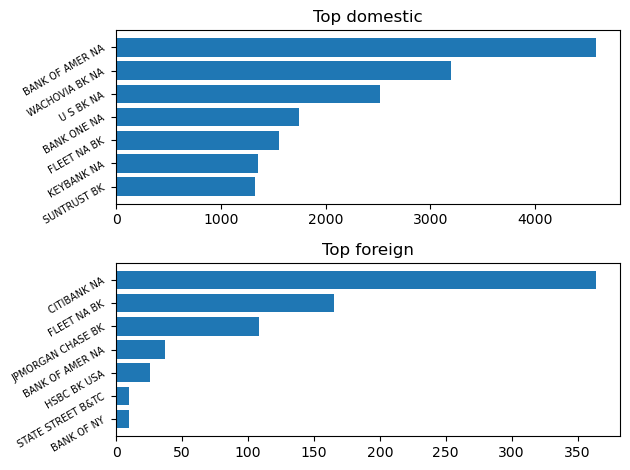

In [17]:
prob7()